In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ml_utils as mu

pred = pd.read_csv("../results/ml/ml_predictions.csv")
comp = pd.read_csv("../results/ml/compounds.csv")
pred = pred.merge(comp[["id", "RotB", "MW", "scaffold"]], on="id")

actives = pred[pred.label == 1]
print("heavy-atom counts of the 40 actives:")
print(sorted(actives["heavy"].tolist()))

print("\nthe ten smallest actives:")
print(actives.nsmallest(10, "heavy")[["id", "heavy", "RotB", "vina_score"]].to_string(index=False))

heavy-atom counts of the 40 actives:
[12, 12, 12, 12, 13, 13, 13, 14, 15, 17, 20, 21, 26, 27, 28, 28, 28, 29, 30, 33, 33, 35, 35, 36, 37, 37, 37, 37, 38, 38, 38, 39, 39, 39, 40, 40, 41, 41, 44, 48]

the ten smallest actives:
         id  heavy  RotB  vina_score
BDB50055163     12     1      -6.302
BDB50055191     12     2      -6.526
BDB50055185     12     1      -6.326
BDB50055204     12     1      -6.489
BDB50055206     13     2      -6.767
BDB50055162     13     2      -6.508
BDB50055180     13     2      -6.545
BDB50008579     14     2      -8.199
    BDB8961     15     0      -8.782
   BDB10516     17     0      -8.914


In [2]:
SMALL_MAX_HEAVY = 21     # sorted active sizes jump from 21 to 26, so the gap sets the cutoff

pred["rank_vina"]   = (-pred["vina_score"]).rank(ascending=False, method="min").astype(int)
pred["rank_size"]   = pred["heavy"].rank(ascending=False, method="min").astype(int)
pred["rank_morgan"] = pred["rf_morgan"].rank(ascending=False, method="min").astype(int)
pred["rank_ifp"]    = pred["rf_ifp"].rank(ascending=False, method="min").astype(int)

small = pred[(pred.label == 1) & (pred.heavy <= SMALL_MAX_HEAVY)].sort_values("heavy")
rest  = pred[(pred.label == 1) & (pred.heavy >  SMALL_MAX_HEAVY)]

print(f"{len(small)} small actives out of {len(pred)} compounds\n")
print(small[["id", "heavy", "RotB", "rank_vina", "rank_size",
             "rank_morgan", "rank_ifp"]].to_string(index=False))

print("\nmedian rank out of 1219:")
for col in ["rank_vina", "rank_size", "rank_morgan", "rank_ifp"]:
    print(f"  {col:12s}  small actives {small[col].median():6.0f}"
          f"     larger actives {rest[col].median():6.0f}")

12 small actives out of 1219 compounds

         id  heavy  RotB  rank_vina  rank_size  rank_morgan  rank_ifp
BDB50055191     12     2       1108       1093          705      1111
BDB50055185     12     1       1121       1093          600       806
BDB50055163     12     1       1123       1093         1126       870
BDB50055204     12     1       1114       1093          892       988
BDB50055162     13     2       1109       1065         1126      1189
BDB50055206     13     2       1084       1065          947      1076
BDB50055180     13     2       1104       1065          500       945
BDB50008579     14     2        970       1050           35       193
    BDB8961     15     0        900       1020           27       398
   BDB10516     17     0        880        969           29       332
BDB50008578     20     3        673        893           31       193
BDB50200343     21     1        719        865           37      1148

median rank out of 1219:
  rank_vina     small ac

In [3]:
ligands = pd.read_csv("../data/dekois_ache/ligands.csv")[["id", "smiles"]]
look = small.merge(ligands, on="id")

sizes = pred.groupby("scaffold").agg(group_n=("id", "size"),
                                     group_actives=("label", "sum")).reset_index()
look = look.merge(sizes, on="scaffold")

for row in look.itertuples():
    print(f"{row.id:14s} heavy {row.heavy:2d}  vina {row.rank_vina:5d}  "
          f"morgan {row.rank_morgan:5d}  scaffold group: {row.group_n} cmpds "
          f"({row.group_actives} active)")
    print(f"               {row.smiles}")

BDB50055191    heavy 12  vina  1108  morgan   705  scaffold group: 14 cmpds (7 active)
               CC[N+](C)(C)c1cc(O)ccc1
BDB50055185    heavy 12  vina  1121  morgan   600  scaffold group: 14 cmpds (7 active)
               Cc1c([N+](C)(C)C)cc(O)cc1
BDB50055163    heavy 12  vina  1123  morgan  1126  scaffold group: 14 cmpds (7 active)
               Cc1c([N+](C)(C)C)cccc1O
BDB50055204    heavy 12  vina  1114  morgan   892  scaffold group: 14 cmpds (7 active)
               Cc1c(O)cc(cc1)[N+](C)(C)C
BDB50055162    heavy 13  vina  1109  morgan  1126  scaffold group: 14 cmpds (7 active)
               Cc1c([N+](C)(C)C)cccc1OC
BDB50055206    heavy 13  vina  1084  morgan   947  scaffold group: 14 cmpds (7 active)
               Cc1c(OC)cc(cc1)[N+](C)(C)C
BDB50055180    heavy 13  vina  1104  morgan   500  scaffold group: 14 cmpds (7 active)
               Cc1c([N+](C)(C)C)cc(cc1)OC
BDB50008579    heavy 14  vina   970  morgan    35  scaffold group: 1 cmpds (1 active)
               C[C@H]

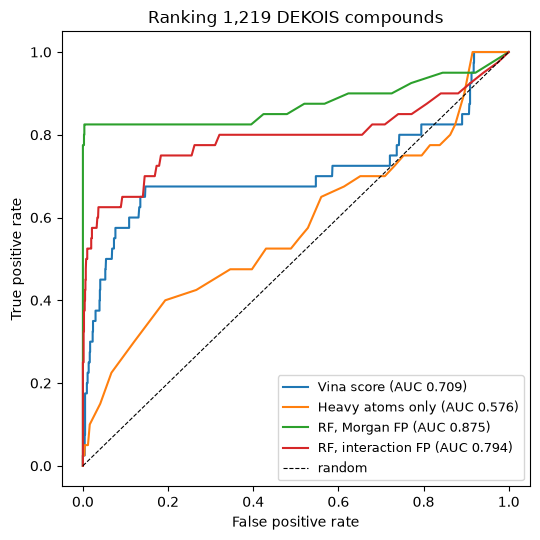

In [4]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(5.5, 5.5))
curves = [
    ("Vina score",           -pred["vina_score"], "AUC 0.709"),
    ("Heavy atoms only",      pred["heavy"],      "AUC 0.576"),
    ("RF, Morgan FP",         pred["rf_morgan"],  "AUC 0.875"),
    ("RF, interaction FP",    pred["rf_ifp"],     "AUC 0.794"),
]
for name, score, label in curves:
    fpr, tpr, _ = roc_curve(pred["label"], score)
    plt.plot(fpr, tpr, label=f"{name} ({label})")

plt.plot([0, 1], [0, 1], "k--", lw=0.8, label="random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Ranking 1,219 DEKOIS compounds")
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig("../results/ml/roc_comparison.png", dpi=150)
plt.show()

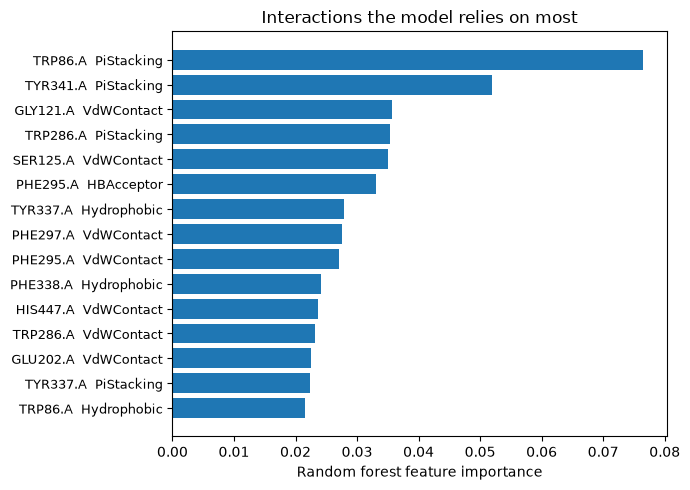

TRP86.A|PiStacking      0.0765
TYR341.A|PiStacking     0.0519
GLY121.A|VdWContact     0.0356
TRP286.A|PiStacking     0.0353
SER125.A|VdWContact     0.0350
PHE295.A|HBAcceptor     0.0331
TYR337.A|Hydrophobic    0.0279
PHE297.A|VdWContact     0.0275
PHE295.A|VdWContact     0.0271
PHE338.A|Hydrophobic    0.0241
HIS447.A|VdWContact     0.0237
TRP286.A|VdWContact     0.0231
GLU202.A|VdWContact     0.0225
TYR337.A|PiStacking     0.0224
TRP86.A|Hydrophobic     0.0215


In [5]:
from sklearn.ensemble import RandomForestClassifier

ifp = pd.read_csv("../results/ml/ifp.csv", index_col=0)
X_ifp = ifp.to_numpy()

# fitted on all 1,219 compounds for interpretation only.
# no performance number is taken from this model, those all come from notebook 07.
rf_full = RandomForestClassifier(n_estimators=500, class_weight="balanced",
                                 random_state=mu.SEED, n_jobs=-1)
rf_full.fit(X_ifp, pred["label"].to_numpy())

imp = pd.Series(rf_full.feature_importances_, index=ifp.columns).nlargest(15)

plt.figure(figsize=(7, 5))
plt.barh(range(len(imp)), imp.values[::-1])
plt.yticks(range(len(imp)), [c.replace("|", "  ") for c in imp.index[::-1]], fontsize=9)
plt.xlabel("Random forest feature importance")
plt.title("Interactions the model relies on most")
plt.tight_layout()
plt.savefig("../results/ml/ifp_feature_importance.png", dpi=150)
plt.show()

print(imp.round(4).to_string())

In [6]:
small.merge(ligands, on="id")[["id", "smiles", "heavy", "RotB", "vina_score",
                               "rank_vina", "rank_size", "rank_morgan", "rank_ifp"]] \
     .to_csv("../results/ml/small_actives_ranks.csv", index=False)

summary = pd.DataFrame({
    "method": ["Vina score", "Heavy atoms only", "RF on Morgan FP", "RF on interaction FP"],
    "median_rank_small_actives":  [small.rank_vina.median(), small.rank_size.median(),
                                   small.rank_morgan.median(), small.rank_ifp.median()],
    "median_rank_larger_actives": [rest.rank_vina.median(), rest.rank_size.median(),
                                   rest.rank_morgan.median(), rest.rank_ifp.median()],
})
summary.to_csv("../results/ml/small_active_recovery.csv", index=False)
imp.to_csv("../results/ml/ifp_feature_importance.csv", header=["importance"])

print(summary.to_string(index=False))
print("\nsaved: small_actives_ranks.csv, small_active_recovery.csv, ifp_feature_importance.csv")

              method  median_rank_small_actives  median_rank_larger_actives
          Vina score                     1094.0                        46.0
    Heavy atoms only                     1065.0                       155.0
     RF on Morgan FP                      550.0                        14.0
RF on interaction FP                      907.5                        17.5

saved: small_actives_ranks.csv, small_active_recovery.csv, ifp_feature_importance.csv
